In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")
print("Dataset shape:", df.shape)

Dataset shape: (891, 12)


Regression dataset: 714 rows
        count       mean        std   min     25%      50%     75%       max
Fare    714.0  34.694514  52.918930  0.00   8.050  15.7417  33.375  512.3292
Pclass  714.0   2.236695   0.838250  1.00   1.000   2.0000   3.000    3.0000
Age     714.0  29.699118  14.526497  0.42  20.125  28.0000  38.000   80.0000
SibSp   714.0   0.512605   0.929783  0.00   0.000   0.0000   1.000    5.0000
Parch   714.0   0.431373   0.853289  0.00   0.000   0.0000   1.000    6.0000


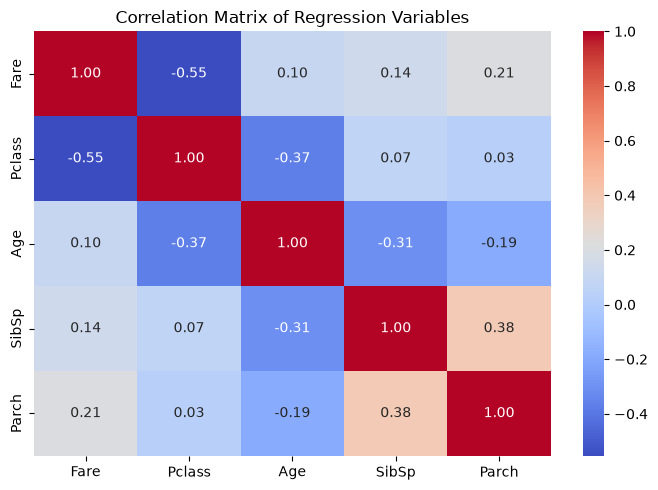

In [3]:
target = "Fare"
predictors = ["Pclass", "Age", "SibSp", "Parch"]
reg_df = df[[target] + predictors].dropna().copy()
print(f"Regression dataset: {len(reg_df)} rows")
print(reg_df.describe().T)

plt.figure(figsize=(7, 5))
sns.heatmap(reg_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix of Regression Variables")
plt.tight_layout()
plt.show()

In [4]:
X, y = reg_df[predictors], reg_df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print("Train set:", len(X_train), "Test set:", len(X_test))

model = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(model.summary())

coefficients = pd.DataFrame({
    "Coefficient": model.params,
    "Std Error": model.bse,
    "t-statistic": model.tvalues,
    "p-value": model.pvalues
})
print(coefficients.round(4))

Train set: 571 Test set: 143
                            OLS Regression Results                            
Dep. Variable:                   Fare   R-squared:                       0.447
Model:                            OLS   Adj. R-squared:                  0.443
Method:                 Least Squares   F-statistic:                     114.3
Date:                Thu, 29 Oct 2026   Prob (F-statistic):           2.24e-71
Time:                        04:01:20   Log-Likelihood:                -2869.6
No. Observations:                 571   AIC:                             5749.
Df Residuals:                     566   BIC:                             5771.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        114.3043  

Train R2: 0.4468 | Adj R2: 0.4428
Test  R2: 0.1774 | RMSE: 58.5198 | MAE: 25.1817


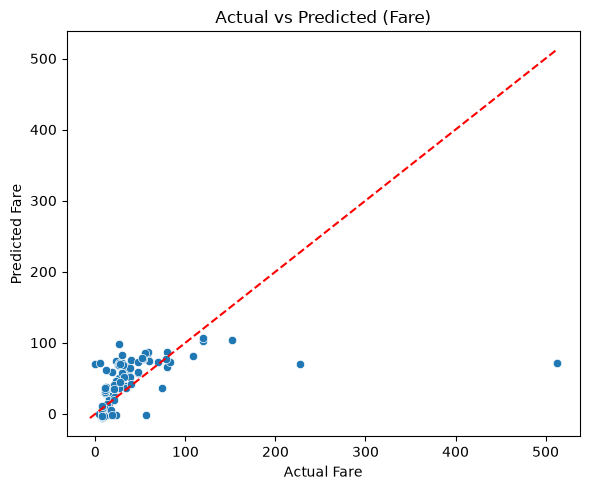

In [5]:
y_pred = model.predict(sm.add_constant(X_test))
mse = mean_squared_error(y_test, y_pred)
rmse, mae = np.sqrt(mse), mean_absolute_error(y_test, y_pred)
test_r2 = r2_score(y_test, y_pred)
print(f"Train R2: {model.rsquared:.4f} | Adj R2: {model.rsquared_adj:.4f}")
print(f"Test  R2: {test_r2:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f}")

plt.figure(figsize=(6, 5))
sns.scatterplot(x=y_test, y=y_pred)
lims = [min(float(y_test.min()), float(y_pred.min())), max(float(y_test.max()), float(y_pred.max()))]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted (Fare)")
plt.tight_layout()
plt.show()

  Variable    VIF
1   Pclass  1.161
2      Age  1.267
3    SibSp  1.218
4    Parch  1.152


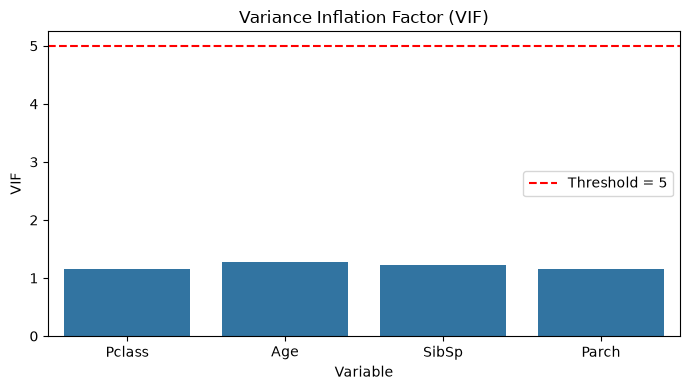

In [6]:
X_vif = sm.add_constant(X_train)
vif = pd.DataFrame({
    "Variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif = vif[vif["Variable"] != "const"]
print(vif.round(3))

plt.figure(figsize=(7, 4))
sns.barplot(data=vif, x="Variable", y="VIF")
plt.axhline(5, color="red", linestyle="--", label="Threshold = 5")
plt.title("Variance Inflation Factor (VIF)")
plt.legend()
plt.tight_layout()
plt.show()

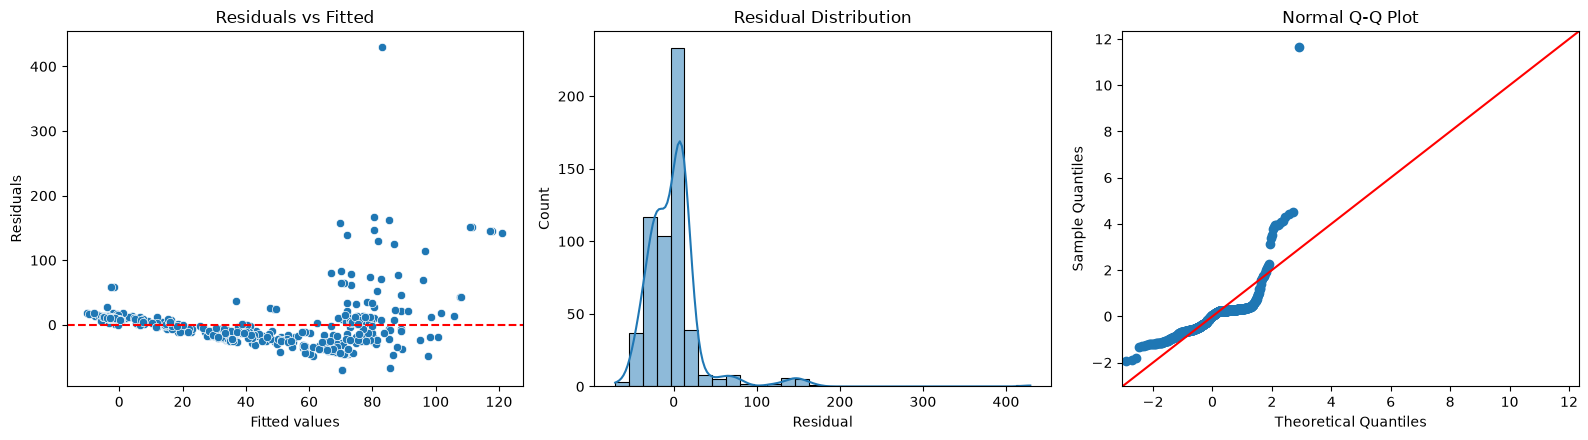

In [7]:
fitted, residuals = model.fittedvalues, model.resid
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.scatterplot(x=fitted, y=residuals, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set(xlabel="Fitted values", ylabel="Residuals", title="Residuals vs Fitted")

sns.histplot(residuals, bins=30, kde=True, ax=axes[1])
axes[1].set(xlabel="Residual", title="Residual Distribution")

sm.qqplot(residuals, line="45", fit=True, ax=axes[2])
axes[2].set(title="Normal Q-Q Plot")
plt.tight_layout()
plt.show()

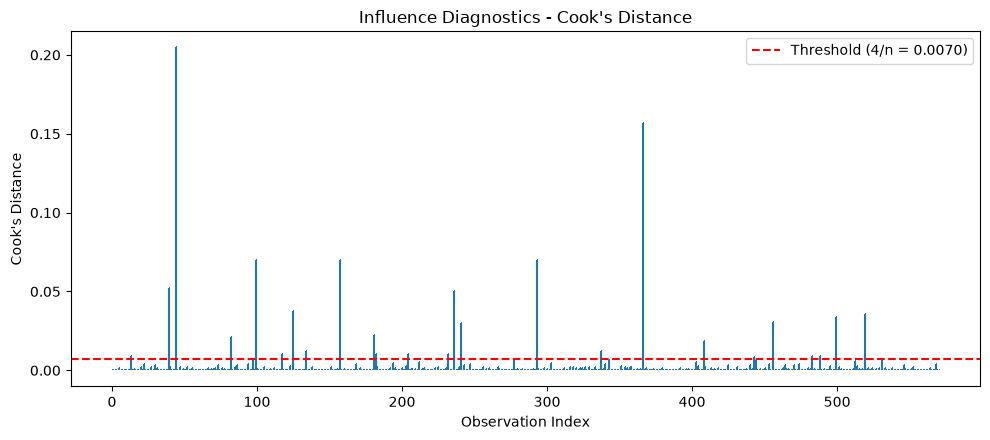

Influential observations count: 25


In [8]:
influence = OLSInfluence(model)
diagnostics = pd.DataFrame({
    "Actual": y_train,
    "Fitted": fitted,
    "Residual": residuals,
    "Std. Residual": influence.resid_studentized_internal,
    "Cook's D": influence.cooks_distance[0]
})
n = len(X_train)
threshold = 4 / n

plt.figure(figsize=(10, 4.5))
plt.stem(np.arange(n), diagnostics["Cook's D"], markerfmt=",", basefmt=" ")
plt.axhline(threshold, color="red", linestyle="--", label=f"Threshold (4/n = {threshold:.4f})")
plt.xlabel("Observation Index")
plt.ylabel("Cook's Distance")
plt.title("Influence Diagnostics - Cook's Distance")
plt.legend()
plt.tight_layout()
plt.show()

influential = diagnostics[diagnostics["Cook's D"] > threshold]
print("Influential observations count:", len(influential))

In [9]:
summary = pd.DataFrame({
    "Metric": ["Training R2", "Adjusted R2", "Test R2", "Test MSE", "Test RMSE", "Test MAE", "Maximum VIF", "Influential observations"],
    "Value": [model.rsquared, model.rsquared_adj, test_r2, mse, rmse, mae, vif["VIF"].max(), len(influential)]
})
print(summary)

coefficients.to_csv("regression_coefficients.csv")
vif.to_csv("vif_results.csv", index=False)
diagnostics.to_csv("regression_diagnostics.csv")
summary.to_csv("regression_summary.csv", index=False)
print("Saved regression results to CSV files.")

                     Metric        Value
0               Training R2     0.446754
1               Adjusted R2     0.442844
2                   Test R2     0.177437
3                  Test MSE  3424.568518
4                 Test RMSE    58.519813
5                  Test MAE    25.181679
6               Maximum VIF     1.267303
7  Influential observations    25.000000
Saved regression results to CSV files.
